# 02 Portfolio Optimization

Goal: build one optimized ETF portfolio for each client, staying inside the allocation limits from `clients.md`.

**Method:** Max Sharpe ratio with PyPortfolioOpt. The Sharpe ratio is (return minus risk-free rate) divided by volatility, so "max Sharpe" means the best return per unit of risk.

**Assumptions (my decisions):**
- Expected returns = historical annual return (CAGR) since late 2007
- Risk = sample covariance of daily returns since late 2007
- Risk-free rate = 2%
- "Stocks" = SPY, IWM, EFA, EEM and VNQ (REITs trade like stocks and fell ~70% in 2008)
- No single ETF above 40%, so the optimizer can't put everything in 1 or 2 funds
- Gold (GLD) capped at 10%. Without a cap the optimizer put 20% to 35% in gold because it had a great run since 2007. Gold is a diversifier, not a core holding
- David: at least 15% MUB. Robert and Linda: at least 5% SHY (about 1.25 years of withdrawals) and at least 10% TIP

## 1. Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pypfopt import expected_returns, risk_models, EfficientFrontier

## 2. Load the price data from notebook 01

In [2]:
prices = pd.read_csv("../data/etf_prices.csv", index_col="Date", parse_dates=True)
tickers = list(prices.columns)
print(prices.index.min().date(), "to", prices.index.max().date())
prices.tail()

2007-09-10 to 2026-11-13


,SPY,IWM,EFA,EEM,AGG,SHY,TIP,MUB,VNQ,GLD
Date,,,,,,,,,,
2026-11-09,752.690002,282.510010,104.959999,61.029999,96.580002,81.589996,106.029999,104.980003,97.300003,379.529999
2026-11-10,749.919983,280.579987,104.360001,60.570000,95.879997,81.320000,105.290001,104.540001,97.080002,369.359985
2026-11-11,759.809998,283.089996,104.660004,62.040001,95.839996,81.309998,105.260002,104.820000,97.019997,365.170013
2026-11-12,757.119995,278.440002,104.010002,61.139999,95.220001,81.139999,104.769997,103.949997,96.440002,354.890015
2026-11-13,753.000000,277.149994,104.035004,60.689701,95.144997,81.195000,104.669998,103.644997,96.355003,355.290009


## 3. Estimate returns and risk

The optimizer needs two inputs:
- **mu**: the expected annual return for each ETF. Here it's just the historical CAGR.
- **S**: the covariance matrix. It holds each ETF's volatility and how much each pair moves together. Low correlation is what makes diversification work.

Big caveat: this assumes the past 18 years tell us something about the future. That's the main weakness of this approach.

In [3]:
mu = expected_returns.mean_historical_return(prices)
S = risk_models.sample_cov(prices)

mu.sort_values(ascending=False).round(3)

SPY    0.110
GLD    0.089
IWM    0.084
VNQ    0.063
EFA    0.047
EEM    0.038
TIP    0.031
MUB    0.029
AGG    0.028
SHY    0.017
dtype: float64

## 4. Tag each ETF with an asset class

This lets me put a min and max on total stocks for each client.

In [4]:
asset_class = {
    "SPY": "stocks", "IWM": "stocks", "EFA": "stocks", "EEM": "stocks", "VNQ": "stocks",
    "AGG": "bonds", "SHY": "bonds", "TIP": "bonds", "MUB": "bonds",
    "GLD": "gold",
}

## 5. Client limits

For each client: the stock range, plus any minimum weights for specific ETFs.

In [5]:
clients = {
    "Maya":            {"stocks_min": 0.80, "stocks_max": 0.95, "minimums": {}},
    "David":           {"stocks_min": 0.50, "stocks_max": 0.65, "minimums": {"MUB": 0.15}},
    "Robert & Linda":  {"stocks_min": 0.30, "stocks_max": 0.45, "minimums": {"SHY": 0.05, "TIP": 0.10}},
}

MAX_WEIGHT = 0.40
GLD_MAX = 0.10
RISK_FREE = 0.02

## 6. The optimizer function

Step by step, this function:
1. Gives every ETF a weight range of 0% to 40% (0% to 10% for GLD). If the client has a minimum for that ETF (like MUB for David), the range starts at that minimum instead of 0%.
2. Builds the optimizer with our return and risk estimates.
3. Adds the rule that total stocks must be between the client's min and max.
4. Finds the max Sharpe portfolio.
5. Rounds tiny weights to 0 (`clean_weights`) and returns the weights plus expected return, volatility and Sharpe.

In [6]:
def optimize_client(limits):
    # 1. Weight range for each ETF
    bounds = []
    for t in tickers:
        low = limits["minimums"].get(t, 0)
        if t == "GLD":
            high = GLD_MAX
        else:
            high = MAX_WEIGHT
        bounds.append((low, high))

    # 2. Set up the optimizer
    ef = EfficientFrontier(mu, S, weight_bounds=bounds)

    # 3. Total stocks must stay in the client's range
    ef.add_sector_constraints(asset_class,
                              {"stocks": limits["stocks_min"]},
                              {"stocks": limits["stocks_max"]})

    # 4. Find the max Sharpe portfolio
    ef.max_sharpe(risk_free_rate=RISK_FREE)

    # 5. Clean up and return results
    weights = ef.clean_weights()
    ret, vol, sharpe = ef.portfolio_performance(risk_free_rate=RISK_FREE)
    return weights, ret, vol, sharpe

## 7. Run it for each client

In [7]:
all_weights = {}
summary = {}

for name, limits in clients.items():
    weights, ret, vol, sharpe = optimize_client(limits)
    all_weights[name] = weights
    summary[name] = {"Expected return": ret, "Volatility": vol, "Sharpe": sharpe}

weights_df = pd.DataFrame(all_weights)
summary_df = pd.DataFrame(summary).T

(weights_df * 100).round(1)

,Maya,David,Robert & Linda
SPY,40.0,40.0,30.0
IWM,40.0,10.0,0.0
EFA,0.0,0.0,0.0
EEM,0.0,0.0,0.0
AGG,0.0,0.0,0.0
SHY,0.0,0.0,5.0
TIP,10.0,25.0,38.1
MUB,0.0,15.0,16.9
VNQ,0.0,0.0,0.0
GLD,10.0,10.0,10.0


Expected return, volatility and Sharpe for each portfolio:

In [8]:
summary_df.round(3)

,Expected return,Volatility,Sharpe
Maya,0.089,0.175,0.397
David,0.073,0.107,0.500
Robert & Linda,0.059,0.070,0.560


Quick check that every client is inside their stock range:

In [9]:
stock_tickers = [t for t in tickers if asset_class[t] == "stocks"]
(weights_df.loc[stock_tickers].sum() * 100).round(1)

Maya              80.0
David             50.0
Robert & Linda    30.0
dtype: float64

## 8. Chart the allocations

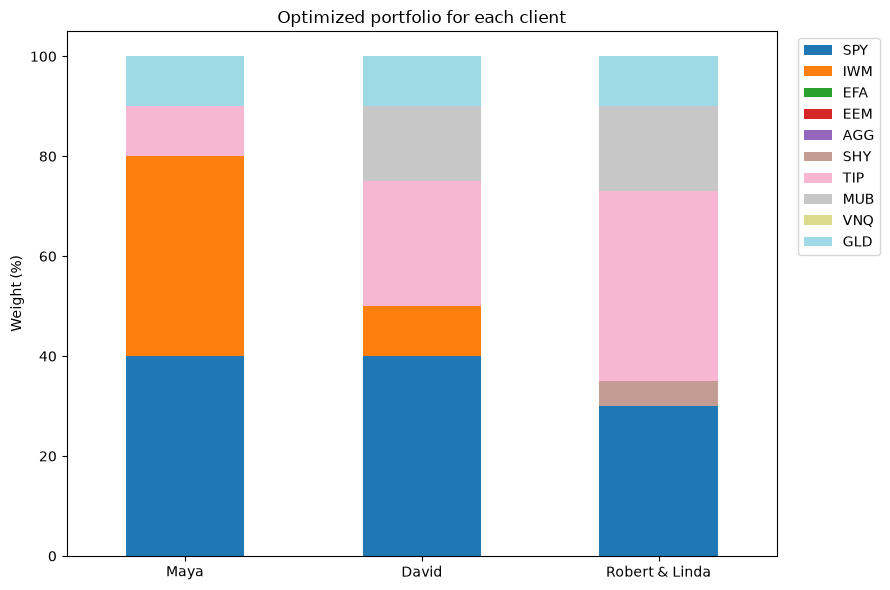

In [10]:
ax = (weights_df.T * 100).plot(kind="bar", stacked=True, figsize=(9, 6), colormap="tab20")
ax.set_ylabel("Weight (%)")
ax.set_title("Optimized portfolio for each client")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../charts/optimized_weights.png", dpi=150)
plt.show()

## 9. Save the weights for the backtest (notebook 03)

In [11]:
weights_df.to_csv("../data/optimized_weights.csv")

## Key takeaways

- (write yours here)